In [12]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown

pd.set_option("display.max_colwidth", None)
pd.options.display.float_format = "{:,.2f}".format

plt.rcParams.update({"font.size": 10.0 * 1.3})

In [13]:
import matplotlib.ticker


def si_format(x, pos):
    return (
        f"{x * 1e-9:1.0f}G"
        if x >= 1e9
        else (
            f"{x * 1e-6:1.0f}M"
            if x >= 1e6
            else f"{x * 1e-3:1.0f}K" if x >= 1e3 else f"{x:1.0f}"
        )
    )


si_formatter = matplotlib.ticker.FuncFormatter(si_format)


def si_format_decimal(x, pos):
    return (
        f"{x * 1e-9:1.1f}G"
        if x >= 1e9
        else (
            f"{x * 1e-6:1.1f}M"
            if x >= 1e6
            else f"{x * 1e-3:1.1f}K" if x >= 1e3 else f"{x:1.1f}"
        )
    )


si_formatter_decimal = matplotlib.ticker.FuncFormatter(si_format_decimal)

In [14]:
def load_benchmark_file(path: str) -> pd.DataFrame:
    with open(path) as file:
        data = json.load(file)

    df = pd.json_normalize(data, record_path="benchmarks")
    df = df.drop(
        columns=[
            "family_index",
            "per_family_instance_index",
            "run_type",
            "repetitions",
            "repetition_index",
            "threads",
            "run_name",
            "iterations",
            "time_unit",
            "real_time",
            "cpu_time",
            "bytes_per_second",
        ],
        errors="ignore",
    )
    df["item_time_ns"] = 1.0 / df["items_per_second"] * 1000 * 1000 * 1000

    return df

In [15]:
NAMESPACE_MAP = {
    "agg_evict": "Agg Evict",
    "pyramid": "Pyramid Sketch",
    "cold_filter": "Cold Filter",
    "python": "SpaceSaving+-",
    "final": "Ours",
}

# ARM GCC 15

In [16]:
df_insert = load_benchmark_file("bm_insert_final_vs_papers.json")

df_insert[["sketch", "data_type"]] = df_insert["name"].str.extract(
    r"BM_Insert<([:\w]+)<([:\w]+)>"
)
df_insert["data_type"] = df_insert["data_type"].str.replace("std::", "")
df_insert["data_type"] = df_insert["data_type"].str.replace("__", "")

df_insert["sketch"] = df_insert["sketch"].str.replace("CountMinSketch", "CountSketch")
df_insert["sketch"] = df_insert["sketch"].str.replace(
    "SpaceSavingSketch", "SpaceSaving"
)
df_insert[["namespace", "sketch"]] = df_insert["sketch"].str.split("::", expand=True)
df_insert = df_insert[
    [
        "namespace",
        "sketch",
        "data_type",
        "item_size",
        "items_per_second",
        "item_time_ns",
    ]
]


## CountSketch

,namespace,sketch,data_type,item_size,items_per_second,item_time_ns,slowdown_over_final
0,final,CountSketch,int16_t,2.00,"163,366,192.33",6.12,1.00
1,final,CountSketch,int32_t,4.00,"163,781,766.08",6.11,1.00
2,final,CountSketch,int64_t,8.00,"163,005,405.63",6.13,1.00
3,final,CountSketch,int128_t,16.00,"121,556,104.77",8.23,1.00
4,final,CountSketch,float,4.00,"161,751,481.50",6.18,1.00
5,final,CountSketch,double,8.00,"161,165,127.29",6.20,1.00
6,final,CountSketch,string,327.00,"17,673,842.18",56.58,1.00
7,pyramid,CountSketch,int16_t,2.00,"20,660,175.57",48.40,7.91
8,pyramid,CountSketch,int32_t,4.00,"19,903,462.68",50.24,8.23
9,pyramid,CountSketch,int64_t,8.00,"16,734,818.53",59.76,9.74


agg_evict max slowdown over final: 10.70x
agg_evict max slowdown over final (no strings): 1.99x
cold_filter max slowdown over final: 19.83x
cold_filter max slowdown over final (no strings): 6.01x
pyramid max slowdown over final: 17.16x
pyramid max slowdown over final (no strings): 10.21x


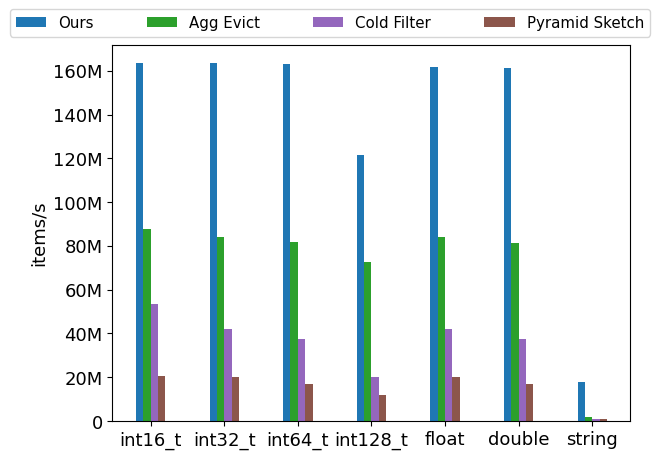

## SpaceSaving

,namespace,sketch,data_type,item_size,items_per_second,item_time_ns,slowdown_over_final
28,final,SpaceSaving,int16_t,2.00,"37,924,210.47",26.37,1.00
29,final,SpaceSaving,int32_t,4.00,"27,491,498.72",36.37,1.00
30,final,SpaceSaving,int64_t,8.00,"15,774,917.45",63.39,1.00
31,final,SpaceSaving,int128_t,16.00,"20,260,394.60",49.36,1.00
32,final,SpaceSaving,float,4.00,"25,607,505.54",39.05,1.00
33,final,SpaceSaving,double,8.00,"16,292,550.68",61.38,1.00
34,final,SpaceSaving,string,327.00,"7,607,576.18",131.45,1.00
35,agg_evict,SpaceSaving,int16_t,2.00,"13,988,478.50",71.49,2.71
36,agg_evict,SpaceSaving,int32_t,4.00,"14,176,013.92",70.54,1.94
37,agg_evict,SpaceSaving,int64_t,8.00,"14,985,118.45",66.73,1.05


cold_filter max slowdown over final: 3.09x
cold_filter max slowdown over final (no strings): 3.09x
agg_evict max slowdown over final: 2.71x
agg_evict max slowdown over final (no strings): 2.71x


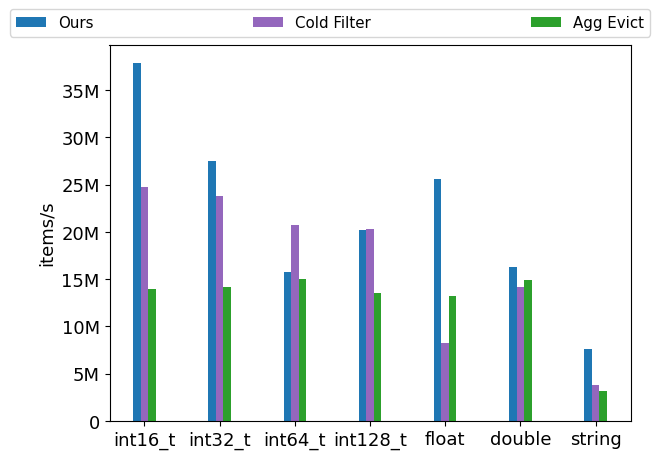

In [17]:
sketches = df_insert["sketch"].unique()

for sketch in sketches:
    for data_type in df_insert["data_type"].unique():
        mask = (df_insert["sketch"] == sketch) & (df_insert["data_type"] == data_type)

        baseline_final = df_insert.loc[
            mask & (df_insert["namespace"] == "final"), "items_per_second"
        ].iloc[0]

        df_insert.loc[mask, "slowdown_over_final"] = (
            baseline_final / df_insert.loc[mask, "items_per_second"]
        )

color_map = {"final": "C0", "naive": "C3", "datasketches": "C1"}

for sketch in sketches:
    display(Markdown(f"## {sketch}"))

    fig, ax = plt.subplots()

    mask = df_insert["sketch"] == sketch
    data = df_insert[mask]

    display(data)

    data_types = data["data_type"].unique()
    x = np.arange(len(data_types))
    width = 0.1

    namespaces = (
        data.groupby("namespace")["items_per_second"]
        .mean()
        .sort_values(ascending=False)
        .index
    )
    for i, namespace in enumerate(namespaces):
        if namespace != "final":
            max_slowdown = data[data["namespace"] == namespace][
                "slowdown_over_final"
            ].max()
            print(f"{namespace} max slowdown over final: {max_slowdown:.2f}x")
            max_slowdown = data[(data["namespace"] == namespace) & (data["data_type"] != "string")][
                "slowdown_over_final"
            ].max()
            print(f"{namespace} max slowdown over final (no strings): {max_slowdown:.2f}x")

        next_color_idx = 1

        mask_ns = data["namespace"] == namespace
        values = []
        for dt in data_types:
            dt_data = data[mask_ns & (data["data_type"] == dt)]["items_per_second"]
            if not dt_data.empty:
                values.append(dt_data.iloc[0])
            else:
                values.append(np.nan)

        color = color_map.get(namespace)
        if color is None:
            while f"C{next_color_idx}" in color_map.values():
                next_color_idx += 1
            color = f"C{next_color_idx}"
            color_map[namespace] = color
            next_color_idx += 1

        ax.bar(
            x + i * width - (len(namespaces) - 1) * width / 2,
            values,
            width,
            label=namespace,
            color=color,
        )

    ax.set_ylabel("items/s")
    ax.set_xticks(x)
    ax.set_xticklabels(data_types)
    ax.yaxis.set_major_formatter(si_formatter)

    handles, labels = ax.get_legend_handles_labels()
    new_labels = [NAMESPACE_MAP.get(label, label) for label in labels]

    ax.legend(
        handles,
        new_labels,
        bbox_to_anchor=(0, 0.9, 1, 0),
        loc="lower left",
        mode="expand",
        borderaxespad=0,
        ncol=4,
        fontsize="small",
        bbox_transform=fig.transFigure,
    )

    fig.tight_layout()
    display(fig)
    plt.close(fig)